In [22]:
# Librerías para datos
import pandas as pd  # Tablas y matrices.
import numpy as np  # Álgebra lineal.


# Librerías para gráficas
import matplotlib.pyplot as plt  # Gráficas básicas.
import seaborn as sns  # Gráficas estadísticas.


# Preparación de datos
from sklearn.model_selection import train_test_split  # División entrenamiento/prueba.


# Modelos de regresión
from sklearn.neighbors import KNeighborsRegressor  # Regresión por vecinos.
from sklearn.ensemble import RandomForestRegressor  # Regresión por árboles.


# Modelos de clasificación
from sklearn.linear_model import LogisticRegression  # Regresión logística.
from sklearn.naive_bayes import GaussianNB  # Clasificación probabilística.
from sklearn.ensemble import RandomForestClassifier  # Clasificación por árboles.
from sklearn.tree import DecisionTreeClassifier  # Clasificación con árbol.


# Métricas
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix  # Métricas de clasificación.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # Métricas de regresión.


# Medición de rendimiento
import time  # Tiempo de ejecución.
import tracemalloc  # Uso de memoria.

In [9]:
# Cargo el Dataset de partidos
df_match = pd.read_csv('../data/processed/clean/Match_Clean.csv')

# Exploración inicial
print(df_match.shape)
display(df_match.head())

# Revisión del conteo de valores nulos por columna
nulos = df_match.isnull().sum()
with pd.option_context('display.max_rows', None):
    display(nulos.to_frame(name='Cantidad de Nulos'))

(3040, 119)


,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,shotoff_total,foulcommit_total,card_total,cross_total,corner_total,home_possession_%,away_possession_%,año,mes,resultado
0,21518,21518,21518,2008/2009,1,2008-08-30,530023,10267,8661,3,...,18.0,30.0,4.0,24.0,11.0,52.0,48.0,2008,8,L
1,21519,21518,21518,2008/2009,1,2008-08-31,530084,8371,10205,1,...,0.0,0.0,5.0,0.0,0.0,NaN,NaN,2008,8,E
2,21520,21518,21518,2008/2009,1,2008-08-31,530085,9783,8633,2,...,10.0,35.0,6.0,34.0,11.0,39.0,61.0,2008,8,L
3,21521,21518,21518,2008/2009,1,2008-08-31,530086,8388,8634,1,...,18.0,22.0,2.0,46.0,9.0,26.0,74.0,2008,8,L
4,21522,21518,21518,2008/2009,1,2008-08-31,530087,8696,8302,1,...,0.0,0.0,2.0,0.0,0.0,NaN,NaN,2008,8,E


,Cantidad de Nulos
id,0
country_id,0
league_id,0
season,0
stage,0
date,0
match_api_id,0
home_team_api_id,0
away_team_api_id,0
home_team_goal,0


### Selección de variables para el modelo

Para construir el predictor de partidos, seleccionaré las variables que aporten información útil al modelo de *Machine Learning*. Las cuotas de las casas de apuestas y las demás columnas se revisarán por separado: las variables elegidas se incorporarán al conjunto de predictores y las restantes quedarán aisladas para no mezclarlas con el entrenamiento.

In [21]:
# Separo las columnas de las casas de apuestas
casas_apuestas = [
    'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'IWH', 'IWD', 'IWA',
    'LBH', 'LBD', 'LBA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA',
    'SJH', 'SJD', 'SJA', 'VCH', 'VCD', 'VCA', 'GBH', 'GBD', 'GBA',
    'BSH', 'BSD', 'BSA'
 ]

# Selecciono las columnas base y los jugadores que voy a analizar
cols_base = ['match_api_id', 'home_team_api_id', 'away_team_api_id', 'home_team_goal', 'away_team_goal', 'season']
cols_jugadores = [f'{side}_player_{i}' for side in ['home', 'away'] for i in range(1, 12)]

# Uno la información en un solo DataFrame
df_matches = df_match[cols_base + casas_apuestas + cols_jugadores].copy()

# En el histórico solo necesito los datos del partido, no descarto partidos por jugadores faltantes
df_historico = df_matches[cols_base + casas_apuestas].dropna(subset=cols_base).copy()

# Clasifico el resultado del partido
def clasificar_resultado(row):
    if row['home_team_goal'] > row['away_team_goal']: return 'L'
    elif row['home_team_goal'] < row['away_team_goal']: return 'V'
    else: return 'E'

df_historico['Resultado'] = df_historico.apply(clasificar_resultado, axis=1)

# Para los enfoques con jugadores, conservo los nulos y los imputo más adelante
df_jugadores_base = df_matches.dropna(subset=cols_base).copy()

print(f"Partidos en el histórico: {len(df_historico)}")
print(f"Partidos listos para trabajar con jugadores: {len(df_jugadores_base)}")
print("\nDistribución de resultados en el histórico:")
display(df_historico['Resultado'].value_counts(normalize=True) * 100)

Partidos en el histórico: 3040
Partidos listos para trabajar con jugadores: 3040

Distribución de resultados en el histórico:


Resultado
L    48.848684
V    27.993421
E    23.157895
Name: proportion, dtype: float64

Tiempo de entrenamiento y predicción: 0.2752 segundos
Consumo máximo de memoria: 4.0399 MB
Accuracy General: 52.89%

Classification Report (Precisión, Recall, F1-Score):
              precision    recall  f1-score   support

           E       0.40      0.04      0.08        92
           L       0.57      0.85      0.68       183
           V       0.44      0.39      0.41       105

    accuracy                           0.53       380
   macro avg       0.47      0.43      0.39       380
weighted avg       0.49      0.53      0.46       380



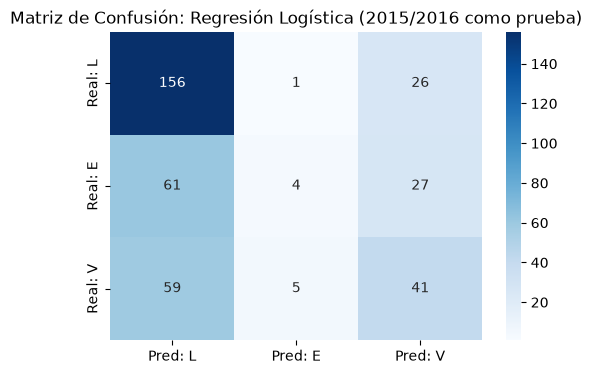

In [34]:
# One-Hot Encoding de los IDs
X_hist = df_historico[['home_team_api_id', 'away_team_api_id']].astype(str)
y_hist = df_historico['Resultado']
X_encoded = pd.get_dummies(X_hist)

# Máscara para separar entrenamiento y prueba (2015/2016 como prueba)
train_mask = df_historico['season'] != '2015/2016'
test_mask = df_historico['season'] == '2015/2016'

X_train_h, y_train_h = X_encoded[train_mask], y_hist[train_mask]
X_test_h, y_test_h = X_encoded[test_mask], y_hist[test_mask]

# Entreno el modelo y mido tiempo y memoria
lr_model = LogisticRegression(max_iter=1000, random_state=42)
tracemalloc.start()
inicio_lr = time.time()
lr_model.fit(X_train_h, y_train_h)
y_pred_lr = lr_model.predict(X_test_h)
_, memoria_max_lr = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_lr = time.time() - inicio_lr
ram_lr_mb = memoria_max_lr / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_lr:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_lr_mb:.4f} MB")
print(f"Accuracy General: {accuracy_score(y_test_h, y_pred_lr) * 100:.2f}%\n")
print("Classification Report (Precisión, Recall, F1-Score):")
print(classification_report(y_test_h, y_pred_lr, zero_division=0))

# Matriz de Confusión
cm = confusion_matrix(y_test_h, y_pred_lr, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Pred: L', 'Pred: E', 'Pred: V'], yticklabels=['Real: L', 'Real: E', 'Real: V'])
plt.title('Matriz de Confusión: Regresión Logística (2015/2016 como prueba)')
plt.show()

Tiempo de entrenamiento y predicción: 0.0256 segundos
Consumo máximo de memoria: 3.0151 MB
Accuracy Naive Bayes: 47.37%

Classification Report:
              precision    recall  f1-score   support

           E       0.34      0.25      0.29        92
           L       0.63      0.54      0.58       183
           V       0.38      0.56      0.45       105

    accuracy                           0.47       380
   macro avg       0.45      0.45      0.44       380
weighted avg       0.49      0.47      0.47       380



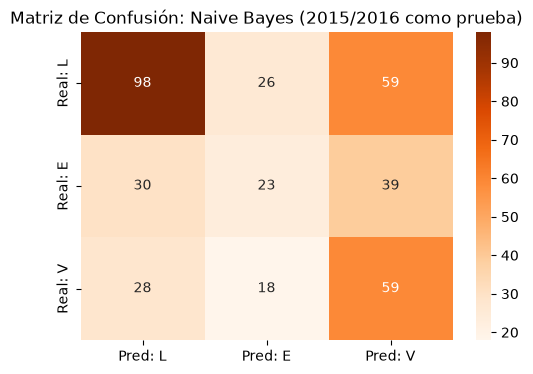

In [38]:
# Entrenamiento de Naive Bayes
nb_model = GaussianNB()
tracemalloc.start()
inicio_nb = time.time()
nb_model.fit(X_train_h.to_numpy(), y_train_h)

# Predigo los resultados de la temporada 2015/2016
y_pred_nb = nb_model.predict(X_test_h.to_numpy())
_, memoria_max_nb = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_nb = time.time() - inicio_nb
ram_nb_mb = memoria_max_nb / (1024 * 1024)

# Muestro las métricas del modelo
print(f"Tiempo de entrenamiento y predicción: {tiempo_nb:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_nb_mb:.4f} MB")
print(f"Accuracy Naive Bayes: {accuracy_score(y_test_h, y_pred_nb) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_h, y_pred_nb, zero_division=0))

# Muestro la matriz de confusión
cm_nb = confusion_matrix(y_test_h, y_pred_nb, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_nb, annot=True, fmt='d', cmap='Oranges',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Matriz de Confusión: Naive Bayes (2015/2016 como prueba)')
plt.show()

Tiempo de entrenamiento y predicción: 0.0730 segundos
Consumo máximo de memoria: 1.4982 MB
Accuracy Árbol de Decisión: 47.37%

Classification Report:
              precision    recall  f1-score   support

           E       0.24      0.21      0.22        92
           L       0.59      0.67      0.63       183
           V       0.41      0.36      0.38       105

    accuracy                           0.47       380
   macro avg       0.41      0.41      0.41       380
weighted avg       0.46      0.47      0.46       380



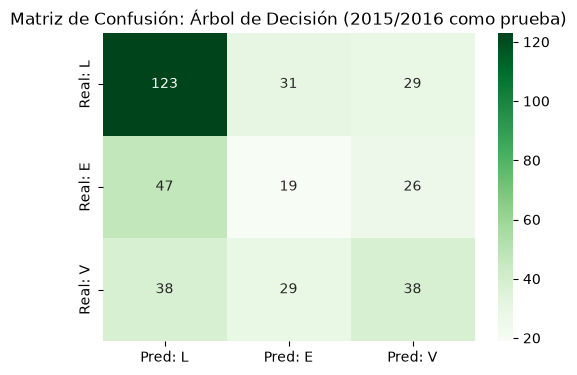

In [41]:
# Entrenamiento de Árbol de Decisión
dt_model = DecisionTreeClassifier(random_state=42)
tracemalloc.start()
inicio_dt = time.time()
dt_model.fit(X_train_h, y_train_h)

# Predigo los resultados de la temporada 2015/2016
y_pred_dt = dt_model.predict(X_test_h)
_, memoria_max_dt = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_dt = time.time() - inicio_dt
ram_dt_mb = memoria_max_dt / (1024 * 1024)

# Muestro las métricas del modelo
print(f"Tiempo de entrenamiento y predicción: {tiempo_dt:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_dt_mb:.4f} MB")
print(f"Accuracy Árbol de Decisión: {accuracy_score(y_test_h, y_pred_dt) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_h, y_pred_dt, zero_division=0))

# Muestro la matriz de confusión
cm_dt = confusion_matrix(y_test_h, y_pred_dt, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_dt, annot=True, fmt='d', cmap='Greens',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Matriz de Confusión: Árbol de Decisión (2015/2016 como prueba)')
plt.show()

Tiempo de entrenamiento y predicción: 3.6838 segundos
Consumo máximo de memoria: 1.3543 MB
Accuracy Random Forest: 47.11%

Classification Report:
              precision    recall  f1-score   support

           E       0.24      0.15      0.19        92
           L       0.57      0.67      0.62       183
           V       0.40      0.40      0.40       105

    accuracy                           0.47       380
   macro avg       0.40      0.41      0.40       380
weighted avg       0.44      0.47      0.45       380



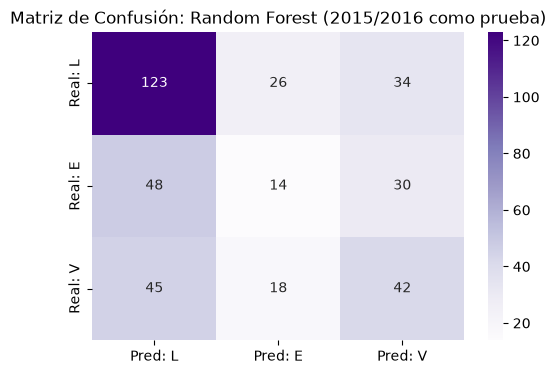

In [44]:
# Entrenamiento de Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
tracemalloc.start()
inicio_rf = time.time()
rf_model.fit(X_train_h, y_train_h)

# Predigo los resultados de la temporada 2015/2016
y_pred_rf = rf_model.predict(X_test_h)
_, memoria_max_rf = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_rf = time.time() - inicio_rf
ram_rf_mb = memoria_max_rf / (1024 * 1024)

# Muestro las métricas del modelo
print(f"Tiempo de entrenamiento y predicción: {tiempo_rf:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_rf_mb:.4f} MB")
print(f"Accuracy Random Forest: {accuracy_score(y_test_h, y_pred_rf) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_h, y_pred_rf, zero_division=0))

# Muestro la matriz de confusión
cm_rf = confusion_matrix(y_test_h, y_pred_rf, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_rf, annot=True, fmt='d', cmap='Purples',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Matriz de Confusión: Random Forest (2015/2016 como prueba)')
plt.show()